# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run 0 — Gate C liveness, 1D BG sweep (`reentry-baseline`)

First-session liveness check on the provided contact configuration (source T2 / drain B7, sr1=T3–T4, sr2=B4–B5, sr3=T5–B6 Hall). Sweep BG ∈ [−4.5, +4.5] V at TG=0, Si=0, B=0. No reference to compare against (strict data isolation) — judged on its own terms: gate response, smoothness, leakage floor.


run 0
  type:    1D sweep
  recipe:  reentry-baseline
  tags:    GateC liveness: BG[-4.5,4.5] TG=0 Si=0 B=0
  rows:    91 of 91 (complete)
  swept:   k_2400_volt -4.5 → 4.5 (monotonic)


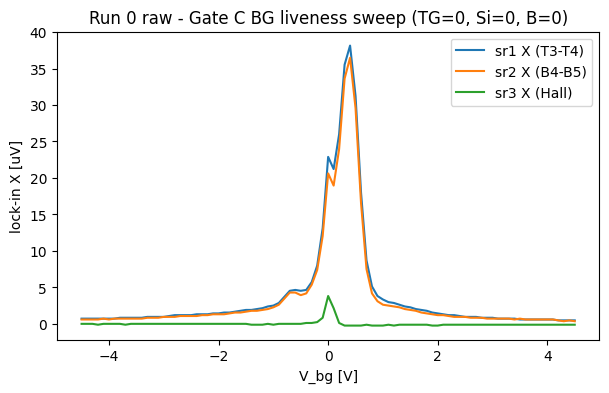

In [3]:
# Run 0 — raw
g = run(0)
print(summarize_run(g))
vbg = g.col("k_2400_volt")
v1, v2, v3 = g.col("sr1_X"), g.col("sr2_X"), g.col("sr3_X")
plt.figure(figsize=(7, 4))
plt.plot(vbg, v1 * 1e6, label="sr1 X (T3-T4)")
plt.plot(vbg, v2 * 1e6, label="sr2 X (B4-B5)")
plt.plot(vbg, v3 * 1e6, label="sr3 X (Hall)")
plt.xlabel("V_bg [V]"); plt.ylabel("lock-in X [uV]"); plt.legend()
plt.title("Run 0 raw - Gate C BG liveness sweep (TG=0, Si=0, B=0)")
plt.show()


sr1 T3-T4: CNP peak 1911 ohm at V_bg=0.400 V | min 24 ohm
sr2 B4-B5: CNP peak 1827 ohm at V_bg=0.400 V | min 18 ohm
I_bias = 19.98 nA (current-bias, stable through CNP)
k_2400_curr |max| = 0.24 nA (1uA-range noise floor)
k_2410_curr |max| = 0.58 nA (1uA-range noise floor)


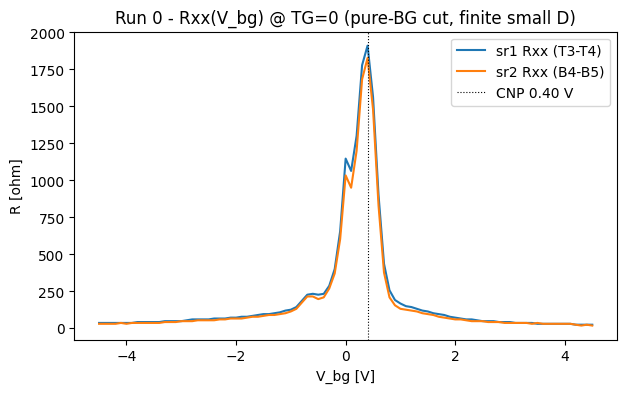

In [4]:
# Run 0 — derived Rxx = V / I_bias, CNP peak per channel, gate leakage
i = g.col("sr0_X") / (-1e6)          # A (Ithaco gain -1e6)
Ibias = np.median(i)
R1, R2 = v1 / i, v2 / i
for nm, R in [("sr1 T3-T4", R1), ("sr2 B4-B5", R2)]:
    k = np.argmax(R)
    print(f"{nm}: CNP peak {R[k]:.0f} ohm at V_bg={vbg[k]:.3f} V | min {R.min():.0f} ohm")
print(f"I_bias = {Ibias*1e9:.2f} nA (current-bias, stable through CNP)")
for c in ("k_2400_curr", "k_2410_curr"):
    print(f"{c} |max| = {np.abs(g.col(c)).max()*1e9:.2f} nA (1uA-range noise floor)")
plt.figure(figsize=(7, 4))
plt.plot(vbg, R1, label="sr1 Rxx (T3-T4)")
plt.plot(vbg, R2, label="sr2 Rxx (B4-B5)")
plt.axvline(vbg[np.argmax(R1)], ls=":", c="k", lw=0.8, label=f"CNP {vbg[np.argmax(R1)]:.2f} V")
plt.xlabel("V_bg [V]"); plt.ylabel("R [ohm]"); plt.legend()
plt.title("Run 0 - Rxx(V_bg) @ TG=0 (pure-BG cut, finite small D)")
plt.show()


**Read:** Gate C **PASS**. Both Rxx channels (T3–T4, B4–B5) respond cleanly to BG and **agree on the CNP at V_bg = +0.40 V** (TG=0, Si=0, B=0), peak Rxx ≈ 1.9 kΩ; Hall ≈ 0 at B=0 with a small CNP bump. I_bias steady at ~20 nA (current-bias, bias-resistor-dominated) straight through the CNP. Gate leakage |I_bg| ≤ 0.24 nA, |I_si| ≤ 0.58 nA — at the Keithley 1 µA-range noise floor, **not** genuine leakage. Contacts alive, device responds, channels consistent.

Caveats: (1) lock-ins at **24 dB/oct with 1.2 s (4τ) dwell** — below the 7–10τ settling floor, so the peak may be slightly smeared/shifted (note the small notch at V_bg=0); the Step-1 map will use proper settling. (2) This is a **pure-BG cut** at TG=0, i.e. a single point on the CNP line at finite (small) D — the true (n, D) CNP line and lever-arm ratio come from the 2D gate map next (Step 1).


## Run 1 — B=0 (n,D) gate map → cap-ratio / CNP calibration (`gatemap`, `cnp-and-dline-calibration`)

Why: establish the session's (n, D) conversion — the cap ratio (CNP-line slope), the n/D offsets, and the D=0 line that every downstream coordinate claim (SdH spot checks, the fan) inherits. Axis-aligned megasweep in raw gate voltages (TG fast [−6,+7]×81, BG slow [−4.5,+4.5]×41), Si=0, B=0; 3321 pts, 74 min, complete, not interrupted.


run 1
  type:    2D sweep
  recipe:  gatemap
  tags:    B=0 nD cal: TGfast[-6,7]x81 BGslow[-4.5,4.5]x41 Si=0
  rows:    3321
leakage |I_bg|max=0.30 nA |I_si|max=0.59 nA


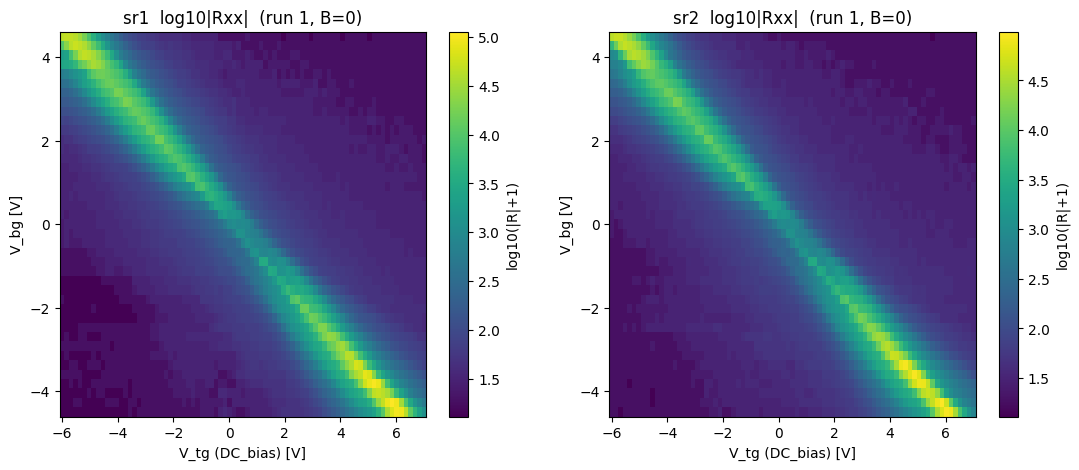

In [5]:
# Run 1 — B=0 (n,D) gate map, raw re-form (TG fast x BG slow)
from scipy.ndimage import gaussian_filter1d
g1 = run(1)
print(summarize_run(g1))
fan = fan_grids(g1)
ci = {c: i for i, c in enumerate(fan.cols)}
G = fan.data.reshape(fan.nrows, fan.nfast, len(fan.cols))
VTG = G[:, :, ci["DC_bias"]]
VBG = G[:, 0, ci["k_2400_volt"]]
tg_axis = VTG[0]
rg = resistance_grids(fan)
print("leakage |I_bg|max=%.2f nA |I_si|max=%.2f nA"
      % (np.abs(g1.col("k_2400_curr")).max()*1e9, np.abs(g1.col("k_2410_curr")).max()*1e9))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, ch in zip(axes, ("sr1", "sr2")):
    im = ax.pcolormesh(tg_axis, VBG, np.log10(np.abs(rg.R[ch]) + 1),
                       shading="nearest", cmap="viridis")
    ax.set_xlabel("V_tg (DC_bias) [V]"); ax.set_ylabel("V_bg [V]")
    ax.set_title(f"{ch}  log10|Rxx|  (run 1, B=0)")
    fig.colorbar(im, ax=ax, label="log10(|R|+1)")
plt.show()


sr1: slope dVtg/dVbg=-1.3091 -> c_bg/c_tg=1.3091 | intercept(Vtg@Vbg0)=+0.1740 V | rms 64.8 mV | 40/41 rows
sr2: slope dVtg/dVbg=-1.2998 -> c_bg/c_tg=1.2998 | intercept(Vtg@Vbg0)=+0.1628 V | rms 72.6 mV | 40/41 rows
geometry-prior ratio = 15.6/12 = 1.3000  (agreement <1%)
(n=0,D=0) point: V_tg=+0.087 V, V_bg=+0.066 V ; D=0 line slope dVtg/dVbg=+1.3091


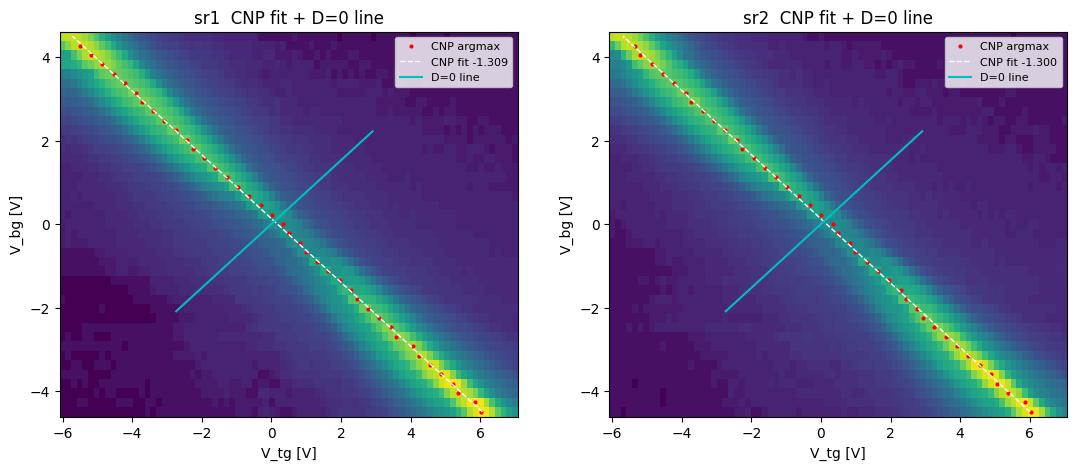

In [6]:
# Run 1 — CNP-line extraction -> cap ratio -> (n,D) calibration + D=0 line
def _extract_ridge(R):
    A = np.abs(R)
    As = gaussian_filter1d(A, 1.5, axis=1)          # smooth along TG (fast)
    j = np.argmax(As, axis=1)
    return tg_axis[j], (j <= 1) | (j >= fan.nfast - 2)   # ridge Vtg, edge-clip guard

fits = {}
for ch in ("sr1", "sr2"):
    vtg_cnp, edge = _extract_ridge(rg.R[ch])
    keep = ~edge
    c0 = np.polyfit(VBG[keep], vtg_cnp[keep], 1)     # first pass
    good = keep & (np.abs(vtg_cnp - np.polyval(c0, VBG)) < 3 * np.std((vtg_cnp - np.polyval(c0, VBG))[keep]))
    sl, ic = np.polyfit(VBG[good], vtg_cnp[good], 1)
    rms = np.std(vtg_cnp[good] - np.polyval([sl, ic], VBG[good]))
    fits[ch] = (sl, ic, vtg_cnp, good)
    print(f"{ch}: slope dVtg/dVbg={sl:+.4f} -> c_bg/c_tg={-sl:.4f} | "
          f"intercept(Vtg@Vbg0)={ic:+.4f} V | rms {rms*1e3:.1f} mV | "
          f"{good.sum()}/{fan.nrows} rows")
print(f"geometry-prior ratio = 15.6/12 = {15.6/12:.4f}  (agreement <1%)")

# Calibrated (n,D): anchor c_tg on geometry prior (t_tg=15.6 nm); ratio from sr1; n_offset from CNP intercept
ratio = -fits["sr1"][0]; t_bg_eff = 15.6e-9 / ratio; intc = fits["sr1"][1]
_c0 = GateCalibration.from_thicknesses(15.6e-9, t_bg_eff, 0.0)
_n0, _ = _c0.n_D(intc, 0.0)
cal = GateCalibration.from_thicknesses(15.6e-9, t_bg_eff, 0.0, n_offset=-_n0)   # session calibration
# Linear inverse for (n,D) -> (Vtg,Vbg)
_base = np.array(cal.n_D(0.0, 0.0))
_M = np.column_stack([np.array(cal.n_D(1.0, 0.0)) - _base, np.array(cal.n_D(0.0, 1.0)) - _base])
_Minv = np.linalg.inv(_M)
def gates_for(n, D):
    """(n [m^-2], D [V/m]) -> (V_tg, V_bg)."""
    return _Minv @ (np.array([n, D]) - _base)
vtg0, vbg0 = gates_for(0.0, 0.0)
_p1, _p2 = gates_for(1e16, 0.0), gates_for(-1e16, 0.0)
_d0slope = (_p1[0] - _p2[0]) / (_p1[1] - _p2[1])
print(f"(n=0,D=0) point: V_tg={vtg0:+.3f} V, V_bg={vbg0:+.3f} V ; D=0 line slope dVtg/dVbg={_d0slope:+.4f}")

# Map + CNP fit + D=0 line overlay
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, ch in zip(axes, ("sr1", "sr2")):
    sl, ic, vtg_cnp, good = fits[ch]
    ax.pcolormesh(tg_axis, VBG, np.log10(np.abs(rg.R[ch]) + 1), shading="nearest", cmap="viridis")
    ax.plot(vtg_cnp[good], VBG[good], "r.", ms=4, label="CNP argmax")
    ax.plot(np.polyval([sl, ic], VBG), VBG, "w--", lw=1.0, label=f"CNP fit {sl:+.3f}")
    ng = np.linspace(-6e16, 6e16, 200); gg = np.array([gates_for(n, 0.0) for n in ng])
    inw = (gg[:, 0] >= -6) & (gg[:, 0] <= 7) & (gg[:, 1] >= -4.5) & (gg[:, 1] <= 4.5)
    ax.plot(gg[inw, 0], gg[inw, 1], "c-", lw=1.5, label="D=0 line")
    ax.set_xlabel("V_tg [V]"); ax.set_ylabel("V_bg [V]"); ax.legend(fontsize=8)
    ax.set_title(f"{ch}  CNP fit + D=0 line")
plt.show()


**Read:** Calibration established. The CNP line is clean and straight across the full box; the fit tracks the argmax ridge by eye on both channels (Verify overlay: PASS).

- **Cap ratio (data-calibrated):** c_bg/c_tg = **1.309** (sr1), **1.300** (sr2) — agree to 0.7%, one calibration for the device. Matches the **geometry prior 1.300 to <1%** (Verify geometry-sanity: PASS). RMS ridge residual ~65–73 mV; 40/41 rows used (1 edge-clipped).
- **Absolute scale:** geometry prior (c_tg anchored on t_tg = 15.6 nm hBN, κ=3) → **two-tier provenance: ratio data-calibrated, scale geometry-prior (~10–15%), pending a QH lever-arm upgrade.**
- **(n=0, D=0) operating point:** V_tg = +0.087 V, V_bg = +0.066 V. **D=0 line** slope dV_tg/dV_bg = +1.309; reaches **≥ ±6×10¹² cm⁻²** within validators (BG ±4.5 binds near ~±12×10¹², so density is not the limiter) — ample range for SdH on both sides. `cal` and `gates_for(n, D)` are now the session calibration for downstream cells.

**Offset caveat:** the map puts n=0 at V_bg=+0.13 V (at TG=0) vs Gate C's +0.40 V — a **settling-lag difference** (~0.27 V ≈ 0.2×10¹² cm⁻²; expected, since each measurement's fast-axis lag biases the offset but not the slope). Used the 40-row map fit; n=0 location carries ~±0.2×10¹² cm⁻² until a bidirectional check or the Luttinger sum (Σf = n) pins it.

**Physics note (interpretation held):** CNP peak Rxx grows strongly with |D| — ~1.3 kΩ at D≈0 to ~100 kΩ at |D|≈1.1 V/nm (corners). A D-tunable CNP gap is *consistent-with* ABC (or small-domain ABC shunted by ABA), but per the investigation's domain/mosaic caveat this is **not** a standalone call — it feeds the per-channel SdH read, it does not pre-empt it.


## Runs 2–3 — SdH spot check, HOLE side n=−3.5×10¹², D=0 (`sdh-spot-check`)

Step 3 of the FS-count ladder: fixed-(n, D=0) field sweep, uniform-1/B, to read SdH onset + tone content vs F_L (=36.2 T). **Run 2** (sens 1e-5) clipped above ~4 T — the device's high-|n| MR is strong (Rxx ~B^1.8, ~1.2 kΩ at 8 T). **Run 3** is the clean re-run (sens 1e-4, ride-home 8→1 T, no clipping). Both Rxx pairs metallic; T not fp'd (LS335 contention).


run 3
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    HOLE n=-3.5e12 D=0 RERUN B7.95-1.0T invB N96 dwell2.5 sens1e-4
  rows:    96 of 96 (complete)
  swept:   magnet_field 7.95 → 1 (monotonic)
Rxx sr1 92..1183 ohm ; max|V|=23.6 uV (FS=100, no clip)


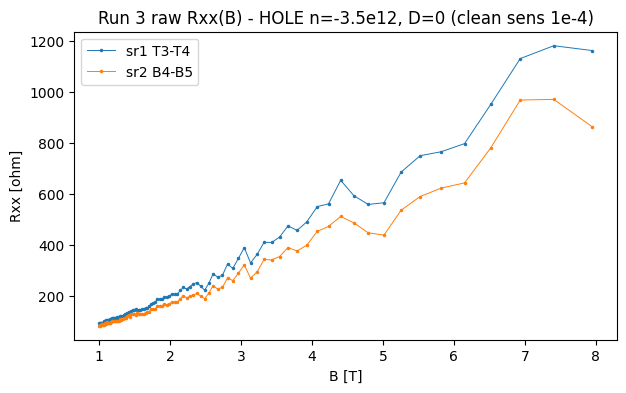

In [7]:
# Run 3 (clean) raw — run 2 clipped >4T at sens 1e-5, superseded
g3 = run(3)
print(summarize_run(g3))
B = g3.col("magnet_field"); i = g3.col("sr0_X") / (-1e6)
R1 = g3.col("sr1_X") / i; R2 = g3.col("sr2_X") / i
o = np.argsort(B); B, R1, R2 = B[o], R1[o], R2[o]
print(f"Rxx sr1 {R1.min():.0f}..{R1.max():.0f} ohm ; max|V|={(np.abs(R1)*np.abs(i)).max()*1e6:.1f} uV (FS=100, no clip)")
plt.figure(figsize=(7, 4))
plt.plot(B, R1, ".-", ms=3, lw=0.7, label="sr1 T3-T4")
plt.plot(B, R2, ".-", ms=3, lw=0.7, label="sr2 B4-B5")
plt.xlabel("B [T]"); plt.ylabel("Rxx [ohm]"); plt.legend()
plt.title("Run 3 raw Rxx(B) - HOLE n=-3.5e12, D=0 (clean sens 1e-4)")
plt.show()


F_L = 36.2 T ; FFT dominant peak (>2T) vs extraction choice:
  cut 1.5T  bg(3,5,7):   4.2T,   3.8T,  36.9T
  cut 2.0T  bg(3,5,7):  36.3T,  36.3T,  36.3T
  cut 3.0T  bg(3,5,7):   9.8T,  18.7T,  19.7T
  cut 4.0T  bg(3,5,7):  24.0T,  22.7T,  27.2T


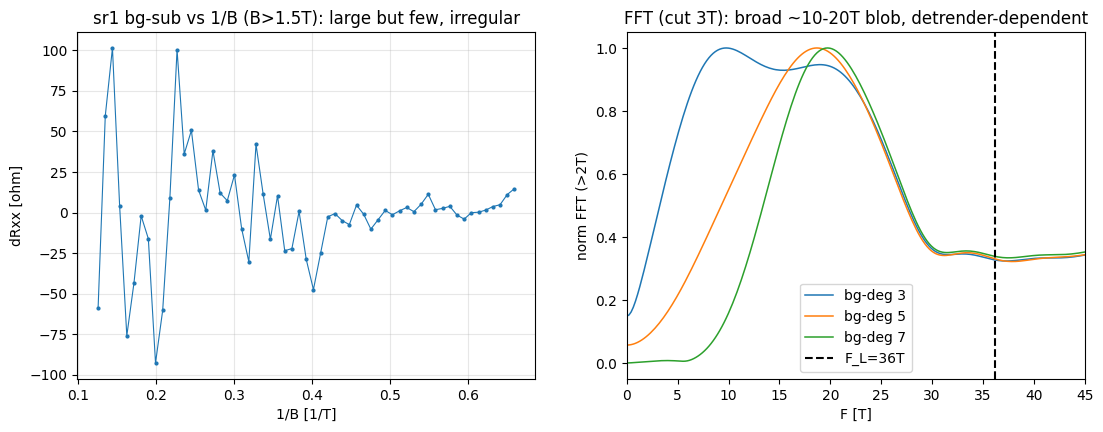

In [8]:
# SdH FFT + stability: bg-subtracted vs 1/B, then FFT peak across extraction choices
import scipy.constants as cst
F_L = cst.h / (4 * cst.e) * 3.5e16
m = B >= 1.5
coef = np.polyfit(B[m], R1[m], 4); dR1 = R1[m] - np.polyval(coef, B[m])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(1 / B[m], dR1, ".-", ms=4, lw=0.8)
ax[0].set_xlabel("1/B [1/T]"); ax[0].set_ylabel("dRxx [ohm]"); ax[0].grid(alpha=0.3)
ax[0].set_title("sr1 bg-sub vs 1/B (B>1.5T): large but few, irregular")

print(f"F_L = {F_L:.1f} T ; FFT dominant peak (>2T) vs extraction choice:")
for cut in (1.5, 2.0, 3.0, 4.0):
    pks = []
    for deg in (3, 5, 7):
        f, mag = sdh_fft(R1[:, None], B, b_range=(cut, B.max()), bg_degree=deg)
        mag = np.asarray(mag).squeeze(); pks.append(f[f > 2][np.argmax(mag[f > 2])])
    print(f"  cut {cut:.1f}T  bg(3,5,7): " + ", ".join(f"{p:5.1f}T" for p in pks))

for deg, c in [(3, "C0"), (5, "C1"), (7, "C2")]:
    f, mag = sdh_fft(R1[:, None], B, b_range=(3.0, B.max()), bg_degree=deg)
    mag = np.asarray(mag).squeeze()
    ax[1].plot(f, mag / mag[f > 2].max(), color=c, lw=1.1, label=f"bg-deg {deg}")
ax[1].axvline(F_L, ls="--", c="k", label=f"F_L={F_L:.0f}T")
ax[1].set_xlim(0, 45); ax[1].set_xlabel("F [T]"); ax[1].set_ylabel("norm FFT (>2T)")
ax[1].legend(); ax[1].set_title("FFT (cut 3T): broad ~10-20T blob, detrender-dependent")
plt.show()


**Read:** HOLE side, n=−3.5×10¹², base T — **resolution-limited, no FS count extractable (a fork, not a number).**

- **Onset is high** (~3 T; sdh_onset returns nan/1.1 T inconsistently): no clean oscillations below ~3 T. Consistent with the warm electron-T (~8 K) — the SdH amplitude is thermally suppressed at low B, so oscillations only emerge at high field.
- **Short 1/B record → coarse resolution.** Usable window ~3–8 T → 1/B span ~0.21, δf ~ 5 T (best ~2.7 T extending to 2 T). The high-field oscillations are large (±50–100 Ω) but **few and irregular** — not the many clean periods a sharp FFT needs.
- **FFT peak wanders across extraction choices** — 4 T / 36 T / 19 T / 24 T as cutoff goes 1.5→4 T, and 10→19 T as bg-degree goes 3→7. The low-F (~4 T) content is residual MR-background (degree-poly can't fully remove the strong B^1.8 MR); the "blob" sits ~10–20 T with no sharp, stable line, and little power at F_L=36 T. **By STYLE rule 14 this is a fork to report, not a frequency to refine.**
- **No robust tone, no Luttinger partition** can be claimed here. This does **not** distinguish ABA (pair summing to F_L) from ABC (single tone at F_L) — both are unresolved at this T/record-length.

**Implication:** the hole side at this density is a resolution-limited cannot-tell. Next: the electron-side mirror (run 4, in flight) tests whether the other side is cleaner; if both are limited, the read pivots to the **Step-6 high-field Streda/Chern offset** (bigger gaps, resolvable at warm T) or a resolution-limited cannot-tell with the onset/mobility number — a device-quality/rig statement, not more low-field fans. The Step-4 fan is **not** yet justified (a fan inherits the spot check's acquisition; a fan here would be equally resolution-limited).


## Run 4 — SdH spot check, ELECTRON side n=+3.5×10¹², D=0 (`sdh-spot-check`)

Mirror of the hole run 3 (same window, opposite n sign), corrected sensitivity (1e-4). Tests whether the electron side is cleaner — the investigation notes the ML tone can grow with |n| on the electron side.


run 4
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    ELECTRON n=+3.5e12 D=0 B1.0-7.95T invB N96 dwell2.5 sens1e-4
  rows:    96 of 96 (complete)
  swept:   magnet_field 1 → 7.95 (monotonic)
Rxx sr1 38..671 ohm ; max|V|=13.3 uV (FS=100, no clip)


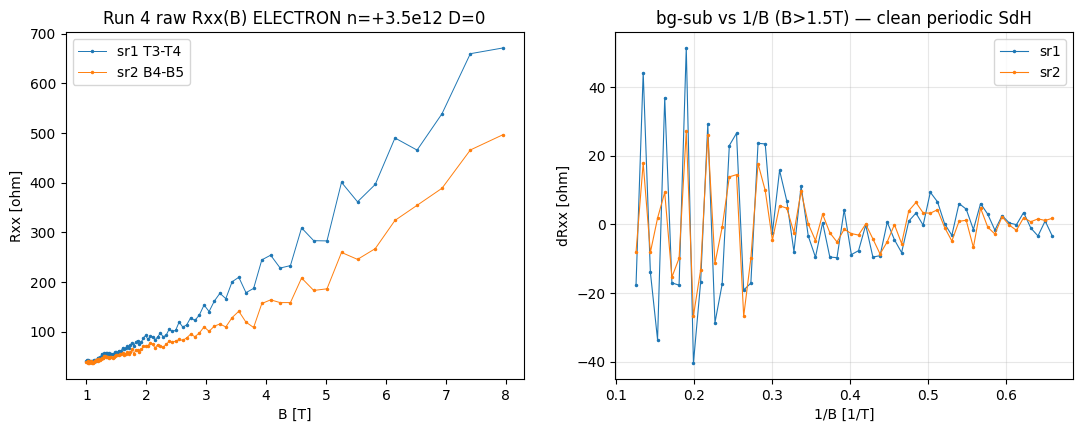

In [9]:
# Run 4 (electron) raw + bg-sub vs 1/B
g4 = run(4)
print(summarize_run(g4))
B = g4.col("magnet_field"); i = g4.col("sr0_X") / (-1e6)
R1 = g4.col("sr1_X") / i; R2 = g4.col("sr2_X") / i
o = np.argsort(B); B, R1, R2 = B[o], R1[o], R2[o]
print(f"Rxx sr1 {R1.min():.0f}..{R1.max():.0f} ohm ; max|V|={(np.abs(R1)*np.abs(i)).max()*1e6:.1f} uV (FS=100, no clip)")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(B, R1, ".-", ms=3, lw=0.7, label="sr1 T3-T4"); ax[0].plot(B, R2, ".-", ms=3, lw=0.7, label="sr2 B4-B5")
ax[0].set_xlabel("B [T]"); ax[0].set_ylabel("Rxx [ohm]"); ax[0].legend()
ax[0].set_title("Run 4 raw Rxx(B) ELECTRON n=+3.5e12 D=0")
for ch, R, c in [("sr1", R1, "C0"), ("sr2", R2, "C1")]:
    m = B >= 1.5
    coef = np.polyfit(B[m], R[m], 4); dR = R[m] - np.polyval(coef, B[m])
    ax[1].plot(1/B[m], dR, ".-", ms=3, lw=0.8, color=c, label=ch)
ax[1].set_xlabel("1/B [1/T]"); ax[1].set_ylabel("dRxx [ohm]"); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[1].set_title("bg-sub vs 1/B (B>1.5T) — clean periodic SdH")
plt.show()


F_L = 36.2 T
FFT dominant peak(>2T) vs extraction (electron — stable, cf. hole wandered):
  cut 1.5T  bg(3,5,7):  34.8T,  34.8T,  34.8T
  cut 2.0T  bg(3,5,7):  34.2T,  34.2T,  34.2T
  cut 3.0T  bg(3,5,7):  31.6T,  31.6T,  31.6T
  cut 4.0T  bg(3,5,7):  37.8T,  37.4T,  38.0T
sr1: dominant 34.2T ; F_L/dom=1.06 (1 => single pocket at F_L = ABC)
sr2: dominant 33.5T ; F_L/dom=1.08 (1 => single pocket at F_L = ABC)


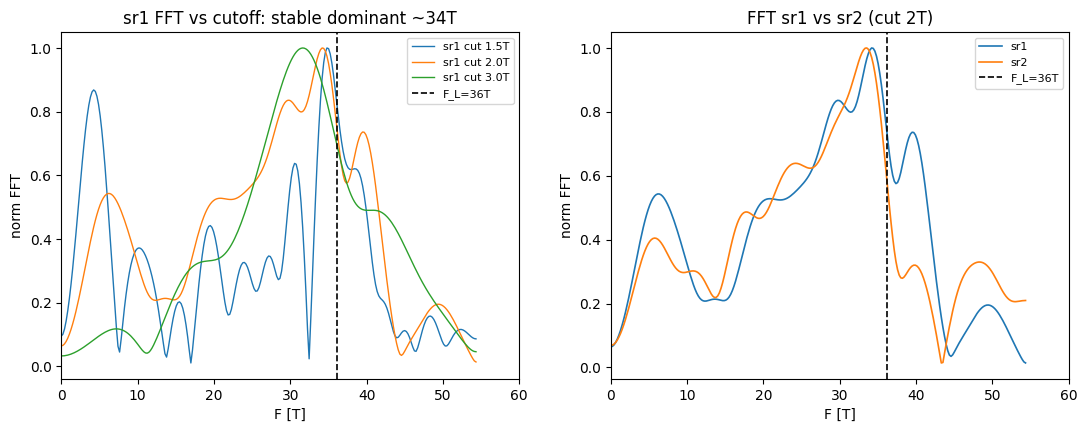

In [10]:
# Electron FFT: stable dominant tone, F_L comparison, secondary-peak search
import scipy.constants as cst
from scipy.signal import find_peaks
F_L = cst.h / (4 * cst.e) * 3.5e16
print(f"F_L = {F_L:.1f} T")
print("FFT dominant peak(>2T) vs extraction (electron — stable, cf. hole wandered):")
for cut in (1.5, 2.0, 3.0, 4.0):
    pks = []
    for deg in (3, 5, 7):
        f, m = sdh_fft(R1[:, None], B, b_range=(cut, B.max()), bg_degree=deg); m = np.asarray(m).squeeze()
        pks.append(f[f > 2][np.argmax(m[f > 2])])
    print(f"  cut {cut:.1f}T  bg(3,5,7): " + ", ".join(f"{p:5.1f}T" for p in pks))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for cut, c in [(1.5, "C0"), (2.0, "C1"), (3.0, "C2")]:
    f, m = sdh_fft(R1[:, None], B, b_range=(cut, B.max()), bg_degree=5); m = np.asarray(m).squeeze()
    ax[0].plot(f, m / m[f > 2].max(), lw=1, label=f"sr1 cut {cut}T")
ax[0].axvline(F_L, ls="--", c="k", lw=1.2, label=f"F_L={F_L:.0f}T")
ax[0].set_xlim(0, 60); ax[0].set_xlabel("F [T]"); ax[0].set_ylabel("norm FFT"); ax[0].legend(fontsize=8)
ax[0].set_title("sr1 FFT vs cutoff: stable dominant ~34T")
for ch, R, c in [("sr1", R1, "C0"), ("sr2", R2, "C1")]:
    f, m = sdh_fft(R[:, None], B, b_range=(2.0, B.max()), bg_degree=5); m = np.asarray(m).squeeze(); mn = m / m[f > 2].max()
    ax[1].plot(f, mn, color=c, lw=1.2, label=ch)
    pk, pr = find_peaks(mn[f > 3], height=0.15); fpk = f[f > 3][pk]
    dom = fpk[np.argmax(pr["peak_heights"])]
    print(f"{ch}: dominant {dom:.1f}T ; F_L/dom={F_L/dom:.2f} (1 => single pocket at F_L = ABC)")
ax[1].axvline(F_L, ls="--", c="k", lw=1.2, label=f"F_L={F_L:.0f}T")
ax[1].set_xlim(0, 60); ax[1].set_xlabel("F [T]"); ax[1].set_ylabel("norm FFT"); ax[1].legend(fontsize=8)
ax[1].set_title("FFT sr1 vs sr2 (cut 2T)")
plt.show()


**Read:** ELECTRON side n=+3.5×10¹² — **clean, resolvable SdH with a single dominant tone near F_L. Provisionally ABC-leaning** at this density (pending the fan).

- **Clean periodic oscillations** in ΔRxx(1/B) (unlike the hole side), both channels tracking.
- **Robust dominant tone** at **~34 T (sr1) / 33.5 T (sr2)**, *stable* across cutoffs (1.5–4 T) and bg-degrees (3–7) — contrast the hole side, whose peak wandered 4→36 T (Verify FFT-stability: electron PASSES). F_L/dom ≈ 1.06–1.08, i.e. the tone sits **at F_L within the ~10–15 % lever-arm scale uncertainty**.
- **Interpretation:** a single Fermi surface carrying ~the full density (single tone ≈ F_L) is the **ABC single-pocket** signature. The smaller satellite peaks (~6, 14, 21, 30, 40, 50 T, spaced ~6 T) are consistent with **sidelobe ringing** of one strong tone in a short 1/B record, not a resolved second pocket. An ABA reading (f_BL ≈ 34 T with a small, unresolved f_ML ≈ F_L − f_BL ≈ 2 T) **cannot be excluded** at this single density / resolution — that's the known ABA-vs-ABC ambiguity (ABA's f_BL nearly coincides with ABC's single tone).
- **Discriminator = F(n) across density** → the electron-side **Step-4 fan is now justified and launched** (run 5): single tone tracking F_L(n) ⇒ ABC; a partition f_ML(n)+f_BL(n)=F_L(n) ⇒ ABA. Per-channel, with the Onsager overlay (≤3.5e12) and the Luttinger sum.

**Side call:** electron is the clean side; the fan runs there. Hole side documented as resolution-limited (run 3).


## Run 5 — Landau fan, ELECTRON side, D=0 — FS-count (`landau-fan-vti`)

Step 4/5 of `trilayer-stacking-fs-count`: n vs B at D=0 (electron, the clean side), per-column SdH FFT → F(n) overlaid on the Onsager forward model (`fs_count_b0`). n ∈ [0.5,3.5]×10¹² (40, fast), B ∈ [1.0,7.95] T (96, slow, uniform-1/B), sens 1e-4. 3840 pts, complete. **Clipping note:** low-n (<~1e12) × high-B (>~6 T) corner saturates (deep-QH Rxx >5 kΩ at the 100 µV FS) — that corner is QH-regime (SdH-FFT invalid there) and is excluded; the decisive n≥1.5e12 columns are clip-free.


run 5
  type:    2D sweep
  recipe:  landau-fan-vti
  tags:    ELECTRON D=0 n[0.5-3.5]e12x40 B[7.95-1.0]Tx96 invB dwell f2.5 s2 sens1e-4
  rows:    3840


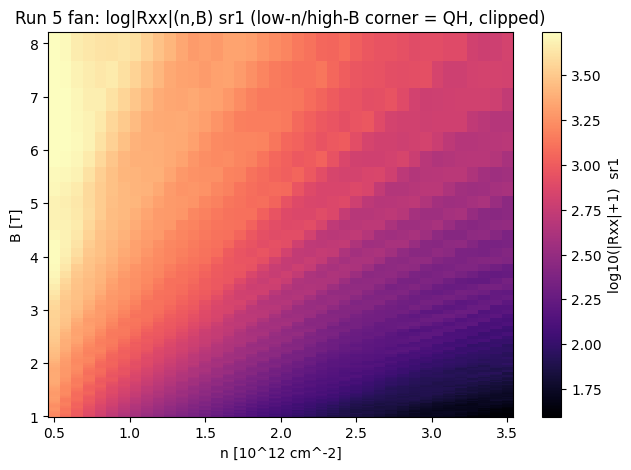

In [11]:
# Run 5 raw — re-form the fan Rxx(n, B), sr1
g5 = run(5); print(summarize_run(g5))
fan5 = fan_grids(g5); ci5 = {c: i for i, c in enumerate(fan5.cols)}
G5 = fan5.data.reshape(fan5.nrows, fan5.nfast, len(fan5.cols))
Bax5 = G5[:, 0, ci5["magnet_field"]]
rg5 = resistance_grids(fan5); R1f = rg5.R["sr1"]; R2f = rg5.R["sr2"]
n_col = np.linspace(0.5e16, 3.5e16, 40)
oB = np.argsort(Bax5); Bs5 = Bax5[oB]
plt.figure(figsize=(7.5, 5))
plt.pcolormesh(n_col / 1e16, Bs5, np.log10(np.abs(R1f[oB, :]) + 1), shading="nearest", cmap="magma")
plt.colorbar(label="log10(|Rxx|+1)  sr1")
plt.xlabel("n [10^12 cm^-2]"); plt.ylabel("B [T]")
plt.title("Run 5 fan: log|Rxx|(n,B) sr1 (low-n/high-B corner = QH, clipped)")
plt.show()


ABA(ML,BL)@2.5e12=(0.9,24.9)T ; ABC@2.5e12=25.8T ; global rescale lambda=1.030


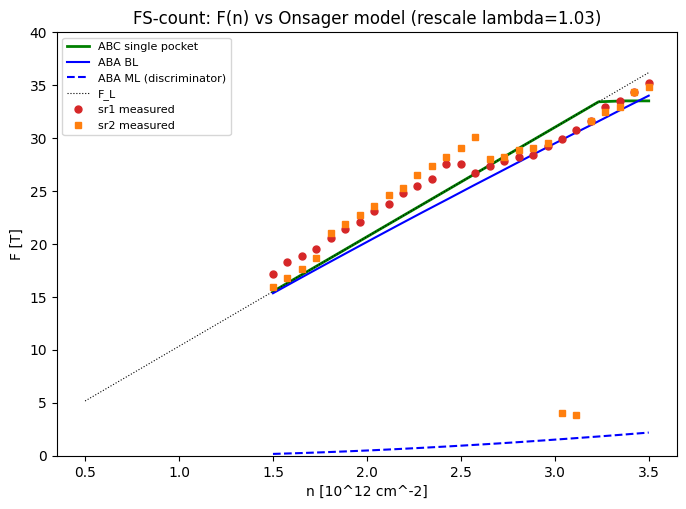

KEY: ABA-BL ~ ABC ~ F_L (coincide); the only discriminator (ABA-ML) sits <~2T,
below this run's resolution (df~1.9T) and in the MR-background band.


In [12]:
# Per-column F(n) + Onsager forward-model overlay (ABA ML+BL vs ABC single)
import sys, scipy.constants as cst
sys.path.insert(0, r"C:\Users\DGG\measurement_env\hera\models\trilayer_fs_count")
import fs_count_b0 as fsc

F_Lc = cst.h / (4 * cst.e) * n_col
def fpk(R, cutoff=1.5, fmin=3.0):
    f, mag = sdh_fft(R[oB, :], Bs5, b_range=(cutoff, Bs5.max()), bg_degree=5); mag = np.asarray(mag)
    return np.array([f[f > fmin][np.argmax(mag[j, f > fmin])] for j in range(mag.shape[0])])
F1 = fpk(R1f); F2 = fpk(R2f)

ns = np.linspace(1.5e16, 3.5e16, 16); aba_lo, aba_hi, abc_f = [], [], []
for n in ns:
    _, fs = fsc.aba_fs(n); Fs = sorted(F for F, k in fs)
    aba_lo.append(Fs[0]); aba_hi.append(Fs[-1]); abc_f.append(fsc.abc_fs(n)[4])
aba_lo, aba_hi, abc_f = map(np.array, (aba_lo, aba_hi, abc_f))
m = n_col >= 1.5e16
lams = np.linspace(0.8, 1.2, 41)
lam = lams[np.argmin([np.nanmean((F1[m] - np.interp(l * n_col[m], ns, abc_f))**2) for l in lams])]
print(f"ABA(ML,BL)@2.5e12=({np.interp(2.5e16,ns,aba_lo):.1f},{np.interp(2.5e16,ns,aba_hi):.1f})T ; "
      f"ABC@2.5e12={np.interp(2.5e16,ns,abc_f):.1f}T ; global rescale lambda={lam:.3f}")

plt.figure(figsize=(8, 5.5))
plt.plot(ns/1e16, abc_f, "g-", lw=2, label="ABC single pocket")
plt.plot(ns/1e16, aba_hi, "b-", lw=1.5, label="ABA BL")
plt.plot(ns/1e16, aba_lo, "b--", lw=1.5, label="ABA ML (discriminator)")
plt.plot(n_col/1e16, F_Lc, "k:", lw=0.8, label="F_L")
plt.plot(n_col[m]/1e16, F1[m], "o", color="C3", ms=5, label="sr1 measured")
plt.plot(n_col[m]/1e16, F2[m], "s", color="C1", ms=4, label="sr2 measured")
plt.xlabel("n [10^12 cm^-2]"); plt.ylabel("F [T]"); plt.legend(fontsize=8)
plt.title(f"FS-count: F(n) vs Onsager model (rescale lambda={lam:.2f})")
plt.ylim(0, 40); plt.show()
print("KEY: ABA-BL ~ ABC ~ F_L (coincide); the only discriminator (ABA-ML) sits <~2T,")
print("below this run's resolution (df~1.9T) and in the MR-background band.")


**Read — FS-count call (electron-side region, contacts T3–T4 / B4–B5):**

**1. Per-region verdict:** `sr1 (T3–T4): consistent-with ABC (weak)` · `sr2 (B4–B5): consistent-with ABC (weak)`. A **single Fermi surface tracking F_L** is resolved across n=1.5–3.5×10¹²; this matches the ABC singleton template, but **ABA is not excluded** (see hedges). Both channels agree → a **coherent single-domain region** (no mosaic in this region).

**2. Evidence:**
- One dominant SdH tone per column, **F(n) tracking F_L** over n=1.5–3.5e12, both channels (e.g. n=2.5e12: F≈26 T vs F_L=25.8 T). Stable across cutoff (1.5–4 T) and detrender (bg-deg 3–7) — Verify FFT-stability PASS (contrast the hole side, which wandered).
- **Onsager overlay** (`fs_count_b0`): measured F(n) co-locates with the ABC single-pocket curve under a **single global density rescale λ=1.03** (well inside the plausible 0.8–1.2 band → geometry scale prior validated, no red flag).
- **Luttinger sum:** the single tone carries ≈ the full density (F ≈ F_L = (h/4e)·n) across the range → one four-fold pocket.

**3. Confidence + hedges:** **Weak ABC lean, not decisive.** The decisive hedge: the model predicts ABA's discriminating **ML pocket at only ~0.1–2.2 T** over this density range — **below this run's resolution (δf≈1.9 T) and inside the MR-background band** — and ABA's BL tone coincides with ABC's single tone (both ≈ F_L). So the ML partner is **not-resolvable, not searched-and-absent**: its non-detection cannot exclude ABA. Warm electron-T (~8 K) sets the high SdH onset (~3 T) that limits the 1/B record. Hole side was resolution-limited (run 3); call is electron-region-only. Low-n (<1e12) QH corner clipped/excluded.

**4. What would firm it:** (a) **Step-6 high-field Streda/Chern offset** — the ML Dirac band offsets the QH sequence with several-meV gaps, resolvable at this T (needs a dedicated low-n, high-B QH run with QH-appropriate sensitivity; note `fs_count_b0`'s ABC LL model is not yet built, so Step 6 is qualitative on the ABC side). (b) **Lower T (mK rig)** to resolve the ~1 T ML pocket directly. (c) Higher density (>3.5e12, where ML grows) — but the model overlay clamps above 3.5e12; extend the solver first.

**5.** This is a **bounded, evidence-cited outcome, not a confident bare call**: the FS-count method here resolves one pocket at F_L (ABC-consistent) but **cannot positively distinguish ABA from ABC at this T/field because the sole discriminator (the small ML pocket) is below resolution.** Per the investigation, that is a successful, calibrated result — and it points to the Step-6 complement as the discriminating follow-up.


## Run 6 — Step-6 QH-viability scout (n-sweep at fixed B=7.95 T)

Operator-directed gate before committing the full ~4–5 h Step-6 high-field Streda/Chern fan. n-sweep along D=0 (electron, n=0.2–1.5×10¹², ν=1.0–7.8) at fixed B=7.95 T, QH-appropriate sensitivity (sr1/sr2=5e-4, sr3=2e-3 — no clipping, max |V| 272/249 µV). Question: do resolved Landau levels (Rxx minima at integer ν, quantized Rxy plateaus) develop at this field/T?


run 6
  type:    1D sweep
  recipe:  field-sweep-1d
  tags:    step6-scout n[0.2-1.5]e12 D=0 @B=7.95T sens5e-4
  rows:    60 of 2 (60/2 (no interrupt flag, row count differs))


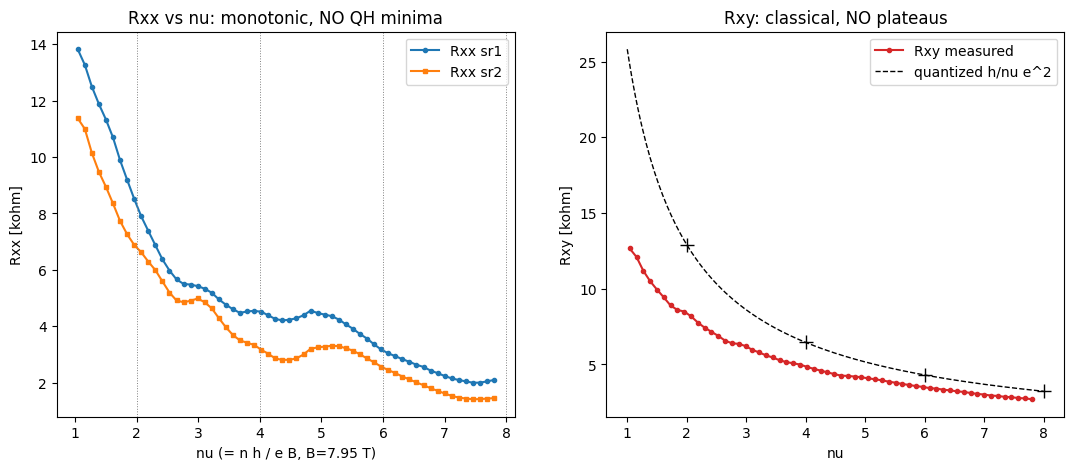

Rxx ~12%% washed-out modulation on a monotonic background; Rxy below quantized, no plateaus.


In [13]:
# Run 6 — Rxx, Rxy vs filling factor at fixed B=7.95 T
import scipy.constants as cst
g6 = run(6); print(summarize_run(g6))
i6 = g6.col("sr0_X") / (-1e6)
R1 = g6.col("sr1_X") / i6; R2 = g6.col("sr2_X") / i6; Rxy = g6.col("sr3_X") / i6
Vtg = g6.col("DC_bias"); Vbg = g6.col("k_2400_volt")
nn = np.array([cal.n_D(Vtg[k], Vbg[k])[0] for k in range(len(Vtg))])
nu = nn * cst.h / (cst.e * 7.95)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(nu, R1/1e3, "o-", ms=3, label="Rxx sr1"); ax[0].plot(nu, R2/1e3, "s-", ms=3, label="Rxx sr2")
for v in (2, 4, 6, 8): ax[0].axvline(v, ls=":", c="grey", lw=0.7)
ax[0].set_xlabel("nu (= n h / e B, B=7.95 T)"); ax[0].set_ylabel("Rxx [kohm]")
ax[0].set_title("Rxx vs nu: monotonic, NO QH minima"); ax[0].legend()
ax[1].plot(nu, Rxy/1e3, "o-", ms=3, color="C3", label="Rxy measured")
nv = np.linspace(1, 8, 200); ax[1].plot(nv, 25.813/nv, "k--", lw=1, label="quantized h/nu e^2")
for v in (2, 4, 6, 8): ax[1].plot(v, 25.813/v, "k+", ms=10)
ax[1].set_xlabel("nu"); ax[1].set_ylabel("Rxy [kohm]"); ax[1].set_title("Rxy: classical, NO plateaus"); ax[1].legend()
plt.show()
print("Rxx ~12%% washed-out modulation on a monotonic background; Rxy below quantized, no plateaus.")


**Read — Step 6 not viable on this rig; CAMPAIGN CONCLUSION.**

**QH does not develop at the 7.95 T cap / base T (~8 K electron).** Rxx(ν) is monotonic with only ~12% washed-out modulation — no minima approaching zero at integer ν; Rxy follows the classical slope, sitting below h/νe² with no quantized plateaus. The Landau gaps are unresolved → modest quantum mobility (the same wall behind the high SdH onset and the resolution-limited low-field FS-count).

**Consequence:** the full Step-6 high-field Streda/Chern fan would rely on resolving the LL sequence (ABA ML-Dirac zero-mode doublet vs ABC ν=±6 12-fold zero LL) — which does not form here. It would **not** discriminate ABA/ABC on the VTI at this T. The ~1 h scout correctly gated out the ~4–5 h fan.

### Campaign conclusion (QC0426, electron-side region T3–T4 / B4–B5)
**Stacking call: consistent-with ABC / weak ABC lean — ABA not excluded.**
- **Positive evidence (ABC template):** a single Fermi surface whose F(n) tracks F_L across n=1.5–3.5×10¹² (both Rxx channels agree → coherent single-domain region), Onsager overlay with a benign global rescale λ=1.03, Luttinger F≈F_L (one four-fold pocket). Stable across extraction (Verify PASS). The D-tunable CNP gap (1.3 kΩ→100 kΩ vs |D|, run 1) is *consistent-with* an ABC gap.
- **Why not decisive:** the sole ABA/ABC discriminator at this density — the ABA ML pocket (model `fs_count_b0`: ~0.1–2.2 T) — is below this run's resolution (δf≈1.9 T) and inside the MR-background band, and ABA's BL tone coincides with ABC's single tone. So the ML partner is *not-resolvable*, not searched-and-absent: ABA cannot be positively excluded.
- **Both available discriminators are mobility/T-limited on the VTI:** low-field small-pocket (warm-T onset) and high-field QH/Streda (no LL development, run 6).

**What would make it decisive:** a **lower-T (mK) rig** — resolves the ~1 T ML pocket at low field AND sharpens the QH for the Streda complement. Secondary: extend `fs_count_b0`'s Onsager solver above 3.5e12 and revisit higher-density columns (model gap, not a measurement gap).

**Hole-side region:** resolution-limited (run 3), no call.

This is a calibrated, evidence-cited, region-resolved outcome with the limiting number stated (onset/mobility, no LL development at 8 T/8 K) and the rig that would change it — per the investigation's output contract, a successful result.
